# Sensitivity Analysis for CCIDeconv

In [2]:
import pandas as pd 
import numpy as np
from sklearn.metrics import classification_report, fbeta_score, f1_score, roc_curve, auc, make_scorer, r2_score, mean_squared_error
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, train_test_split, cross_val_predict
from category_encoders import CatBoostEncoder
from sklearn.preprocessing import OneHotEncoder
import random
import seaborn as sns
from collections import Counter
from bayes_opt import BayesianOptimization
from sklearn.preprocessing import StandardScaler as sc
from xgboost import XGBClassifier
from sklearn import preprocessing 
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support, balanced_accuracy_score, classification_report, r2_score, mean_squared_error, fbeta_score
from scipy.stats import norm
from sklearn.datasets import make_classification 
# from imblearn.combine import SMOTETomek
# from imblearn.under_sampling import RandomUnderSampler
# from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight
# from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import classification_report
from sklearn.feature_selection import SelectFromModel
from sklearn.base import clone
from collections import defaultdict
from matplotlib.colors import to_rgb
# from imblearn.combine import SMOTEENN
import matplotlib.patches as mpatches
import pickle
from sklearn.decomposition import PCA
from xgboost import XGBRegressor
from sklearn.preprocessing import MultiLabelBinarizer
import re
from scipy.stats import boxcox
from scipy.special import inv_boxcox
random.seed(42) 
from scipy.stats import false_discovery_control

In [5]:
# scaling function
def scale_continuous_by_group(X, groups, cont_cols):
    X_scaled = X.copy()
    groups_array = np.array(groups)  # ensures it's index-aligned with X
    for g in np.unique(groups_array):
        idx = np.where(groups_array == g)[0] 
        X_scaled.loc[X.iloc[idx].index, cont_cols] = pd.DataFrame(sc().fit_transform(X.iloc[idx][cont_cols]), columns=cont_cols, index=X.iloc[idx].index)
    return X_scaled

seed = 112 

# bayesian optimization function
def rf_cv(max_samples,n_estimators,max_features, max_depth, min_samples_split, min_samples_leaf):
    params = {
        'max_samples': max_samples,
        'max_features':max_features,
        'n_estimators':int(n_estimators),
        'random_state': 42,
        'max_depth': int(max_depth),
        'min_samples_split': int(min_samples_split),
        'min_samples_leaf': int(min_samples_leaf)
    }
    estimator_function = RandomForestClassifier(**params)
    estimator_function.fit(X_train,y_train)
    probs = estimator_function.predict(X_train)
    f1 = f1_score(y_train,probs, average='macro')
    return f1

def xgbc_cv(max_depth,learning_rate,n_estimators,reg_alpha,colsample_bytree, min_child_weight, gamma, scale_pos_weight):
    estimator_function = xgb.XGBClassifier(max_depth=int(max_depth),
                                           colsample_bytree= colsample_bytree,
                                           gamma= gamma,
                                           min_child_weight= int(min_child_weight),
                                           learning_rate= learning_rate,
                                           n_estimators= int(n_estimators),
                                           reg_alpha = reg_alpha,
                                           nthread = -1,
                                           objective='binary:logistic',
                                           scale_pos_weight = scale_pos_weight,
                                           seed = seed)
    # estimator_function.fit(X_train,y_train)
    # probs = estimator_function.predict(X_train)
    scores = cross_val_score(estimator_function, X_train, y_train, cv=3,
                             scoring='f1_macro', n_jobs=-1)
    # f1 = f1_score(y_train, probs, average='macro')
    return scores.mean()

def xgb_reg(max_depth, learning_rate, n_estimators, reg_alpha, colsample_bytree, min_child_weight, gamma):
    max_depth = int(max_depth)
    n_estimators = int(n_estimators)
    estimator_function = XGBRegressor(
        max_depth=max_depth,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        reg_alpha=reg_alpha,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        gamma=gamma,
        objective='reg:squarederror',
        random_state=seed,
        n_jobs=-1
    )
    scores = []
    # Fit the estimator
    estimator_function.fit(X_train_reg,y_train_reg)
    y_pred = estimator_function.predict(X_test_reg)
    score = r2_score(y_test_reg, y_pred)
    return score

In [11]:
df = pd.read_csv('../../../data/training_data/training_data.csv') #read the data 
# 1. Convert columns to float to allow decimal calculation
df['cell_pval'] = df['cell_pval'].astype(float)
df['cyt_pval'] = df['cyt_pval'].astype(float)
df['nuc_pval'] = df['nuc_pval'].astype(float)

# 2. Apply False Discovery Control
df['cell_padj'] = false_discovery_control(df["cell_pval"], method="bh")
df['cyt_padj'] = false_discovery_control(df["cyt_pval"], method="bh")
df['nuc_padj'] = false_discovery_control(df["nuc_pval"], method="bh")
print(len(df))
# 3. Filter rows
df = df[(df['cell_padj'] <= 0.05) & (df['cyt_padj'] <= 0.05) & (df['nuc_padj'] <= 0.05)]
print(len(df))
# generate labels
conditions = [
    (df['cyt_score'] == 0) & 
    (df['nuc_score'] == 0), # detected in cell alone
    (df['cyt_score'] > 0) & 
    (df['nuc_score'] > 0), # detected in both cytoplasm and nucleus + cell
    (df['cyt_score'] > 0) & 
    (df['nuc_score'] == 0), # detected in cytoplasm + cell alone
    (df['nuc_score'] > 0) & 
    (df['cyt_score'] == 0), # detected in nucleus + cell alone
]
labels = [0,1,1,1]
df['labels'] = np.select(conditions, labels, default=4)
df = df[df['labels'] != 4] # remove the non significant interactions if any

# columns to remove from the x_matric
exclude_columns = [
    'cyt_pval', 'cyt_pspatial', 'cyt_P1', 'sample',
    'cell_pval', 'cell_P1', 'tissue', 'is_neurotransmitter',
    'ligand_location_cellchat', 'receptor_location_cellchat',
    'ligand_location_hpa', 'receptor_location_hpa',
    'nuc_pval', 'nuc_pspatial', 'nuc_P1', 'ligand', 'receptor', 
]
X = df.drop(columns=exclude_columns)
groups = df['sample'].values
cont_cols = ['cell_score', 'cell_pspatial', 'nuc_score', 'cyt_score']
X_scaled = scale_continuous_by_group(X, groups, cont_cols) # scaling the continuous columns
y_nuc = X_scaled[['nuc_score']]
y_cyt = X_scaled[['cyt_score']]

# Catboost encoding
catboost_encoder = CatBoostEncoder()
categorical_columns = ['lr_pair', 'source', 'target',
    'pathway_name', 'annotation',
    'ligand.family', 'ligand.keyword', 'ligand.secreted_type',
    'ligand.transmembrane', 'receptor.family',
    'receptor.keyword', 'receptor.surfaceome_main',
    'receptor.surfaceome_sub', 'receptor.adhesome',
    'receptor.secreted_type', 'receptor.transmembrane']
labels = ['labels']
# catboost_encoded = catboost_encoder.fit_transform(X_scaled[categorical_columns], X[labels])
# X_scaled = X_scaled.drop(categorical_columns, axis = 1)
# X_scaled = pd.concat([X_scaled.reset_index(drop= True), catboost_encoded.reset_index(drop = True)], axis = 1)
y = df['labels']
X_scaled = X_scaled.drop(columns=['cyt_score', 'nuc_score']) # remove the labels column from the x matrix
ids = df[['lr_pair', 'source', 'target']]

3273
962


/var/folders/7q/h5n0rm1d6bs8yprnqc04_5740000gp/T/ipykernel_7123/356819424.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['cell_padj'] = false_discovery_control(df["cell_pval"], method="bh")
/var/folders/7q/h5n0rm1d6bs8yprnqc04_5740000gp/T/ipykernel_7123/356819424.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['cyt_padj'] = false_discovery_control(df["cyt_pval"], method="bh")
/var/folders/7q/h5n0rm1d6bs8yprnqc04_5740000gp/T/ipykernel_7123/356819424.py:10: PerformanceWarning: DataFrame is highly fragmented.  This i

In [ ]:
# random forest model optimization
def rf_cv(max_samples,n_estimators,max_features, max_depth, min_samples_split, min_samples_leaf, X_train, y_train):
    params = {
        'max_samples': max_samples,
        'max_features':max_features,
        'n_estimators':int(n_estimators),
        'random_state': 42,
        'max_depth': int(max_depth),
        'min_samples_split': int(min_samples_split),
        'min_samples_leaf': int(min_samples_leaf)
    }
    estimator_function = RandomForestClassifier(**params)
    f1_scores = cross_val_score(estimator_function, X_train, y_train, cv=3,
                             scoring='f1_macro', n_jobs=-1)
    return f1_scores.mean()

hyperparameter_space_rf_class =  {'max_samples':(0.1,1),
              'max_features':(0.3,1),
              'n_estimators':(150,300),
              'max_depth':(5,30),
              'min_samples_split':(2,10),
              'min_samples_leaf':(2,10)
              }

hyperparameter_space_xgb_class = {
    'max_depth': (6, 10),
    'learning_rate': (0.01, 0.3),
    'n_estimators' : (100,300),
    'reg_alpha': (0,1),
    'min_child_weight': (1, 20),
    'colsample_bytree': (0.5, 1),
    'gamma' : (0,5),
    'scale_pos_weight': (1, 100)
}

# xgb classification optimization
def xgbc_cv(max_depth,learning_rate,n_estimators,reg_alpha,colsample_bytree, min_child_weight, gamma, scale_pos_weight, X_train, y_train):
    estimator_function = xgb.XGBClassifier(max_depth=int(max_depth),
                                           colsample_bytree= colsample_bytree,
                                           gamma= gamma,
                                           min_child_weight= int(min_child_weight),
                                           learning_rate= learning_rate,
                                           n_estimators= int(n_estimators),
                                           reg_alpha = reg_alpha,
                                           nthread = -1,
                                           objective='binary:logistic',
                                           scale_pos_weight = scale_pos_weight,
                                           seed = 112)
    f1_scores = cross_val_score(estimator_function, X_train, y_train, cv=3,
                             scoring='f1_macro', n_jobs=-1)
    return f1_scores.mean()

# xgb regression optimization
def xgb_reg(max_depth, learning_rate, n_estimators, reg_alpha, colsample_bytree, min_child_weight, gamma, X_train_reg, y_train_reg):
    max_depth = int(max_depth)
    n_estimators = int(n_estimators)
    estimator_function = xgb.XGBRegressor(
        max_depth=max_depth,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        reg_alpha=reg_alpha,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        gamma=gamma,
        objective='reg:squarederror',
        random_state=112,
        n_jobs=-1
    )
    # Fit the estimator
    cv = KFold(n_splits=3, shuffle=True, random_state=112)
    scores = cross_val_score(estimator_function, X_train_reg, y_train_reg, cv=cv,
                             scoring=make_scorer(r2_score))
    return scores.mean()

In [ ]:
import warnings
warnings.filterwarnings('ignore')
gp_params = {"alpha": 1e-10}
seed = 112 

# hyperparameter space for binary classification
hyperparameter_space_rf_class =  {'max_samples':(0.1,1),
              'max_features':(0.3,1),
              'n_estimators':(150,300),
              'max_depth':(5,30),
              'min_samples_split':(2,10),
              'min_samples_leaf':(2,10)
              }

hyperparameter_space_xgb_class = {
    'max_depth': (6, 10),
    'learning_rate': (0.01, 0.3),
    'n_estimators' : (100,300),
    'reg_alpha': (0,1),
    'min_child_weight': (1, 20),
    'colsample_bytree': (0.5, 1),
    'gamma' : (0,5),
    'scale_pos_weight': (1, 100)
}

X_scaled = X_scaled.drop(['labels'], axis = 1)
logo = LeaveOneGroupOut() # leave one group out

# init dicts and lists
classification_metrics = {}
cyt_metrics ={}
nuc_metrics = {}
scatter_data_cyt = {}
scatter_data_nuc = {}
parameters = []
classification_preds = {}
regression_cyt = {}
regression_nuc = {}
roc_tables = {}
# loop for training with leave one group out
for train_index, test_index in logo.split(X_scaled, y, groups):
    ############+++++++++++++++++++++++++++++++++++++++++++++++++ Classification ++++++++++++++++++++++++++++++++++++++++#############
    # prepare train and test data
    X_train = X_scaled.iloc[train_index, :]  
    X_test = X_scaled.iloc[test_index, :]
    y_train = y.iloc[train_index].values.ravel()  
    y_test = y.iloc[test_index].values.ravel()
    
    test_ids = ids.iloc[test_index]

    # encoding the test and train to prevent data leakage
    catboost_encoded = catboost_encoder.fit_transform(X_train[categorical_columns], y_train)
    X_train = X_train.drop(categorical_columns, axis = 1)
    X_train = pd.concat([X_train.reset_index(drop= True), catboost_encoded.reset_index(drop = True)], axis = 1)
    
    catboost_encoded = catboost_encoder.transform(X_test[categorical_columns])
    X_test = X_test.drop(categorical_columns, axis = 1)
    X_test = pd.concat([X_test.reset_index(drop= True), catboost_encoded.reset_index(drop = True)], axis = 1)
    
    # convert to numpy
    X_train = X_train.to_numpy(dtype=np.float32)  
    y_train = y_train.ravel().astype(np.int32)
    X_test = X_test.to_numpy(dtype=np.float32)  
    y_test = y_test.ravel().astype(np.int32)
    
    # hyperparameter tuning - RF
    # xgbcBO = BayesianOptimization(f = rf_cv, 
    #                             pbounds =  hyperparameter_space_rf_class,
    #                             random_state = seed,
    #                             verbose = 10)
    xgbcBO = BayesianOptimization(
        f=lambda **params: rf_cv(**params, X_train=X_train, y_train=y_train),
        pbounds=hyperparameter_space_rf_class,
        random_state=seed,
        verbose=0
    )
    
    xgbcBO.maximize(init_points=3,n_iter=30)
    params = xgbcBO.max['params']
    
    #### Training and prediction - RF
    model1 = RandomForestClassifier(max_samples=params['max_samples'], max_features= params['max_features'],
                       min_samples_split= int(params['min_samples_split']), max_depth=int(params['max_depth']),
                       min_samples_leaf= int(params['min_samples_leaf']), n_estimators=int(params['n_estimators']))
    model1.fit(X_train, y_train) # fit the model 

    # hyperparameter tuning -XGB
    # xgbcBO = BayesianOptimization(f = xgbc_cv, 
    #                             pbounds =  hyperparameter_space_xgb_class,
    #                             random_state = seed,
    #                             verbose = 10)
    xgbcBO = BayesianOptimization(
        f=lambda **params: xgbc_cv(**params, X_train=X_train, y_train=y_train),
        pbounds=hyperparameter_space_xgb_class,
        random_state=seed,
        verbose=0
    )
    xgbcBO.set_gp_params(**gp_params)
    xgbcBO.maximize(init_points=3,n_iter=30)
    params = xgbcBO.max['params']
    
    #### Training and prediction - XGB
    model2 = XGBClassifier(colsample_bytree=params['colsample_bytree'], gamma= params['gamma'],
                       learning_rate= params['learning_rate'], max_depth=int(params['max_depth']),
                       min_child_weight= params['min_child_weight'], n_estimators=int(params['n_estimators']),
                       reg_alpha= params['reg_alpha'], scale_pos_weight = params[ 'scale_pos_weight']) # initialize the model 
    model2.fit(X_train, y_train) # fit the model 

    #Voting
    model = VotingClassifier(
    estimators=[('rf', model1), ('xgb', model2)],
    voting='soft')
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)        
    
    #### Evaluation 
    cm = confusion_matrix(y_test, y_pred) # confusion matrix
    from sklearn.metrics import balanced_accuracy_score
    print(classification_report(y_test, y_pred))
    fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    metrics = {
        'accuracy': balanced_accuracy_score(y_test, y_pred),
        'class_report': classification_report(y_test, y_pred),
        'cm': cm,
        'f2':fbeta_score(y_test, y_pred,  beta = 2, average = 'binary'),
        'f1': f1_score(y_test, y_pred, average= 'macro'), 
        'roc_auc':  auc(fpr, tpr)
    }
    roc_table = pd.DataFrame({
        'False Positive Rate': fpr,
        'True Positive Rate': tpr,
        'Thresholds': thresholds
    })
    
    group_name = np.unique(groups[test_index])[0] #get the group name to store the metrics
    classification_metrics[group_name] = metrics
    predictions_classification = pd.DataFrame({f'pred_{group_name}': y_pred, f'true_{group_name}': y_test}) # create a dataframe to store the predictions
    classification_preds[group_name] = predictions_classification
    roc_tables[group_name] = roc_table 
    
    
    ############+++++++++++++++++++++++++++++++++++++++++++++++++ REGRESSION FRAMEWORK ++++++++++++++++++++++++++++++++++++++++#############
    # prepare the train and test datasets
    train_mask = (y.iloc[train_index].values.ravel() == 1) # get the indices where y == 1 in the training indexes the true y to train on
    X_train_reg = X_train[train_mask]
    y_train_reg = y_cyt.iloc[train_index].values.ravel()[train_mask]
    test_conf_mask = y_pred == 1 
    X_test_reg = X_test[test_conf_mask] # the pred positives to test on 
    y_test_reg = y_cyt.iloc[test_index].values.ravel()[test_conf_mask]
    
    cyt_test_ids = test_ids.iloc[test_conf_mask]

    ##### CYTOPLASMIC 
    # regression hyperparameters to optimize   
    hyperparameter_space_reg = {
    'max_depth': (10, 20),
    'learning_rate': (0.01, 0.1),
    'n_estimators' : (100, 300),
    'reg_alpha': (0, 1),
    'min_child_weight': (1, 3),
    'colsample_bytree': (0.8, 1),
    'gamma' : (0, 3)}
    
    # hyperparameter tuning
    # xgb_bo = BayesianOptimization(f=xgb_reg,
    #     pbounds=hyperparameter_space_reg,
    #     random_state=seed,
    #     verbose=0
    # )
    xgb_bo = BayesianOptimization(
        f=lambda **params: xgb_reg(**params, X_train_reg=X_train_reg, y_train_reg=y_train_reg),
        pbounds=hyperparameter_space_reg,
        random_state=seed,
        verbose=0
    )
    xgb_bo.set_gp_params(**gp_params)
    xgb_bo.maximize(init_points=3, n_iter=30)
    best_params = xgb_bo.max['params']

    #### Training and prediction
    model = XGBRegressor(
        max_depth=int(best_params['max_depth']),
        learning_rate=best_params['learning_rate'],
        n_estimators=int(best_params['n_estimators']),
        reg_alpha=best_params['reg_alpha'],
        colsample_bytree=best_params['colsample_bytree'],
        min_child_weight=best_params['min_child_weight'],
        gamma=best_params['gamma'],
        objective='reg:squarederror',
        eval_metric='rmse',
        early_stopping_rounds=50, 
        random_state=seed,
        n_jobs=-1
    )
    model.fit(X_train_reg, y_train_reg, eval_set=[(X_test_reg, y_test_reg)])
    y_pred_reg = model.predict(X_test_reg)

    # Evaluation
    metrics = {"R²": r2_score(y_test_reg, y_pred_reg),
               'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
               'NRMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))/np.std(y_test_reg)}
    
    cyt_metrics[group_name] = metrics
    
    scatter_data_cyt[group_name] = {
    'true': y_test_reg.copy(),
    'pred': y_pred_reg.copy(),
    'title': f'Cytoplasm: {group_name}',
    'ids': cyt_test_ids}
    
    predictions_reg = pd.DataFrame({f'pred_{group_name}': y_pred_reg, f'true_{group_name}': y_test_reg}) # create a dataframe to store the predictions
    regression_cyt[group_name] = predictions_reg
    
    ##### NUCLEUS 
    # Prepare test [training is the same as cytoplasmic regression]
    y_train_reg = y_nuc.iloc[train_index].values.ravel()[train_mask]
    y_test_reg = y_nuc.iloc[test_index].values.ravel()[test_conf_mask]
    
    nuc_test_ids = test_ids.iloc[test_conf_mask]
    
    # hyperparameter tuning
    # xgb_bo = BayesianOptimization(f=xgb_reg,
    #     pbounds=hyperparameter_space_reg,
    #     random_state=seed,
    #     verbose=0
    # )
    xgb_bo = BayesianOptimization(
        f=lambda **params: xgb_reg(**params, X_train_reg=X_train_reg, y_train_reg=y_train_reg),
        pbounds=hyperparameter_space_reg,
        random_state=seed,
        verbose=0
    )
    xgb_bo.set_gp_params(**gp_params)
    xgb_bo.maximize(init_points=3, n_iter=30)
    best_params = xgb_bo.max['params']

    # Train and predict
    model = XGBRegressor(
        max_depth=int(best_params['max_depth']),
        learning_rate=best_params['learning_rate'],
        n_estimators=int(best_params['n_estimators']),
        reg_alpha=best_params['reg_alpha'],
        colsample_bytree=best_params['colsample_bytree'],
        min_child_weight=best_params['min_child_weight'],
        gamma=best_params['gamma'],
        objective='reg:squarederror',
        eval_metric='rmse',
        early_stopping_rounds=50, 
        random_state=seed,
        n_jobs=-1
    )
    model.fit(X_train_reg, y_train_reg, eval_set=[(X_test_reg, y_test_reg)])
    y_pred_reg = model.predict(X_test_reg)

    # --- Evaluation ---
    scatter_data_nuc[group_name] = {
    'true': y_test_reg.copy(),
    'pred': y_pred_reg.copy(),
    'title': f'Nucleus: {group_name}',
    'ids': nuc_test_ids}
    
    metrics = {"R²": r2_score(y_test_reg, y_pred_reg),
               'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
               'NRMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))/np.std(y_test_reg)}
    nuc_metrics[group_name] = metrics
    
    predictions_reg = pd.DataFrame({f'pred_{group_name}': y_pred_reg, f'true_{group_name}': y_test_reg}) # create a dataframe to store the predictions
    regression_nuc[group_name] = predictions_reg

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
/opt/anaconda3/lib

              precision    recall  f1-score   support

           0       0.45      1.00      0.62        13
           1       1.00      0.63      0.77        43

    accuracy                           0.71        56
   macro avg       0.72      0.81      0.70        56
weighted avg       0.87      0.71      0.74        56

[0]	validation_0-rmse:1.31525
[1]	validation_0-rmse:1.29964
[2]	validation_0-rmse:1.28428
[3]	validation_0-rmse:1.26930
[4]	validation_0-rmse:1.25454
[5]	validation_0-rmse:1.24004
[6]	validation_0-rmse:1.22451
[7]	validation_0-rmse:1.20725
[8]	validation_0-rmse:1.19013
[9]	validation_0-rmse:1.17333
[10]	validation_0-rmse:1.15694
[11]	validation_0-rmse:1.14071
[12]	validation_0-rmse:1.12483
[13]	validation_0-rmse:1.10938
[14]	validation_0-rmse:1.09392
[15]	validation_0-rmse:1.07889
[16]	validation_0-rmse:1.06410
[17]	validation_0-rmse:1.04960
[18]	validation_0-rmse:1.03501
[19]	validation_0-rmse:1.02067
[20]	validation_0-rmse:1.00670
[21]	validation_0-rmse:0.99282
[

In [ ]:
import warnings
warnings.filterwarnings('ignore')
gp_params = {"alpha": 1e-10}
seed = 112 

# hyperparameter space for binary classification
hyperparameter_space_rf_class =  {'max_samples':(0.1,1),
              'max_features':(0.3,1),
              'n_estimators':(150,300),
              'max_depth':(5,30),
              'min_samples_split':(2,10),
              'min_samples_leaf':(2,10)
              }

hyperparameter_space_xgb_class = {
    'max_depth': (6, 10),
    'learning_rate': (0.01, 0.3),
    'n_estimators' : (100,300),
    'reg_alpha': (0,1),
    'min_child_weight': (1, 20),
    'colsample_bytree': (0.5, 1),
    'gamma' : (0,5),
    'scale_pos_weight': (1, 100)
}

X_scaled = X_scaled.drop(['labels'], axis = 1)
logo = LeaveOneGroupOut() # leave one group out

# init dicts and lists
classification_metrics = {}
cyt_metrics ={}
nuc_metrics = {}
scatter_data_cyt = {}
scatter_data_nuc = {}
parameters = []
classification_preds = {}
regression_cyt = {}
regression_nuc = {}
roc_tables = {}
# loop for training with leave one group out
for train_index, test_index in logo.split(X_scaled, y, groups):
    ############+++++++++++++++++++++++++++++++++++++++++++++++++ Classification ++++++++++++++++++++++++++++++++++++++++#############
    # prepare train and test data
    X_train = X_scaled.iloc[train_index, :]  
    X_test = X_scaled.iloc[test_index, :]
    y_train = y.iloc[train_index].values.ravel()  
    y_test = y.iloc[test_index].values.ravel()
    
    test_ids = ids.iloc[test_index]

    # encoding the test and train to prevent data leakage
    catboost_encoded = catboost_encoder.fit_transform(X_train[categorical_columns], y_train)
    X_train = X_train.drop(categorical_columns, axis = 1)
    X_train = pd.concat([X_train.reset_index(drop= True), catboost_encoded.reset_index(drop = True)], axis = 1)
    
    catboost_encoded = catboost_encoder.transform(X_test[categorical_columns])
    X_test = X_test.drop(categorical_columns, axis = 1)
    X_test = pd.concat([X_test.reset_index(drop= True), catboost_encoded.reset_index(drop = True)], axis = 1)
    
    # convert to numpy
    X_train = X_train.to_numpy(dtype=np.float32)  
    y_train = y_train.ravel().astype(np.int32)
    X_test = X_test.to_numpy(dtype=np.float32)  
    y_test = y_test.ravel().astype(np.int32)
    
    # hyperparameter tuning - RF
    xgbcBO = BayesianOptimization(f = rf_cv, 
                                pbounds =  hyperparameter_space_rf_class,
                                random_state = seed,
                                verbose = 10)
    xgbcBO.maximize(init_points=3,n_iter=30)
    params = xgbcBO.max['params']
    
    #### Training and prediction - RF
    model1 = RandomForestClassifier(max_samples=params['max_samples'], max_features= params['max_features'],
                       min_samples_split= int(params['min_samples_split']), max_depth=int(params['max_depth']),
                       min_samples_leaf= int(params['min_samples_leaf']), n_estimators=int(params['n_estimators']))
    model1.fit(X_train, y_train) # fit the model 

    # hyperparameter tuning -XGB
    xgbcBO = BayesianOptimization(f = xgbc_cv, 
                                pbounds =  hyperparameter_space_xgb_class,
                                random_state = seed,
                                verbose = 10)
    xgbcBO.set_gp_params(**gp_params)
    xgbcBO.maximize(init_points=3,n_iter=30)
    params = xgbcBO.max['params']
    
    #### Training and prediction - XGB
    model2 = XGBClassifier(colsample_bytree=params['colsample_bytree'], gamma= params['gamma'],
                       learning_rate= params['learning_rate'], max_depth=int(params['max_depth']),
                       min_child_weight= params['min_child_weight'], n_estimators=int(params['n_estimators']),
                       reg_alpha= params['reg_alpha'], scale_pos_weight = params[ 'scale_pos_weight']) # initialize the model 
    model2.fit(X_train, y_train) # fit the model 

    #Voting
    model = VotingClassifier(
    estimators=[('rf', model1), ('xgb', model2)],
    voting='soft')
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)        
    
    #### Evaluation 
    cm = confusion_matrix(y_test, y_pred) # confusion matrix
    from sklearn.metrics import balanced_accuracy_score
    print(classification_report(y_test, y_pred))
    fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    metrics = {
        'accuracy': balanced_accuracy_score(y_test, y_pred),
        'class_report': classification_report(y_test, y_pred),
        'cm': cm,
        'f2':fbeta_score(y_test, y_pred,  beta = 2, average = 'binary'),
        'f1': f1_score(y_test, y_pred, average= 'macro'), 
        'roc_auc':  auc(fpr, tpr)
    }
    roc_table = pd.DataFrame({
        'False Positive Rate': fpr,
        'True Positive Rate': tpr,
        'Thresholds': thresholds
    })
    
    group_name = np.unique(groups[test_index])[0] #get the group name to store the metrics
    classification_metrics[group_name] = metrics
    predictions_classification = pd.DataFrame({f'pred_{group_name}': y_pred, f'true_{group_name}': y_test}) # create a dataframe to store the predictions
    classification_preds[group_name] = predictions_classification
    roc_tables[group_name] = roc_table 
    
    
    ############+++++++++++++++++++++++++++++++++++++++++++++++++ REGRESSION FRAMEWORK ++++++++++++++++++++++++++++++++++++++++#############
    # prepare the train and test datasets
    train_mask = (y.iloc[train_index].values.ravel() == 1) # get the indices where y == 1 in the training indexes
    X_train_reg = X_train[train_mask]
    y_train_reg = y_cyt.iloc[train_index].values.ravel()[train_mask]
    test_conf_mask = y_pred == 1 
    X_test_reg = X_test[test_conf_mask]
    y_test_reg = y_cyt.iloc[test_index].values.ravel()[test_conf_mask]
    
    cyt_test_ids = test_ids.iloc[test_conf_mask]

    ##### CYTOPLASMIC 
    # regression hyperparameters to optimize   
    hyperparameter_space_reg = {
    'max_depth': (10, 20),
    'learning_rate': (0.01, 0.1),
    'n_estimators' : (100, 300),
    'reg_alpha': (0, 1),
    'min_child_weight': (1, 3),
    'colsample_bytree': (0.8, 1),
    'gamma' : (0, 3)}
    
    # hyperparameter tuning
    xgb_bo = BayesianOptimization(f=xgb_reg,
        pbounds=hyperparameter_space_reg,
        random_state=seed,
        verbose=0
    )
    xgb_bo.set_gp_params(**gp_params)
    xgb_bo.maximize(init_points=3, n_iter=30)
    best_params = xgb_bo.max['params']

    #### Training and prediction
    model = XGBRegressor(
        max_depth=int(best_params['max_depth']),
        learning_rate=best_params['learning_rate'],
        n_estimators=int(best_params['n_estimators']),
        reg_alpha=best_params['reg_alpha'],
        colsample_bytree=best_params['colsample_bytree'],
        min_child_weight=best_params['min_child_weight'],
        gamma=best_params['gamma'],
        objective='reg:squarederror',
        eval_metric='rmse',
        early_stopping_rounds=50, 
        random_state=seed,
        n_jobs=-1
    )
    model.fit(X_train_reg, y_train_reg, eval_set=[(X_test_reg, y_test_reg)])
    y_pred_reg = model.predict(X_test_reg)

    # Evaluation
    metrics = {"R²": r2_score(y_test_reg, y_pred_reg),
               'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
               'NRMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))/np.std(y_test_reg)}
    
    cyt_metrics[group_name] = metrics
    
    scatter_data_cyt[group_name] = {
    'true': y_test_reg.copy(),
    'pred': y_pred_reg.copy(),
    'title': f'Cytoplasm: {group_name}',
    'ids': cyt_test_ids}
    
    predictions_reg = pd.DataFrame({f'pred_{group_name}': y_pred_reg, f'true_{group_name}': y_test_reg}) # create a dataframe to store the predictions
    regression_cyt[group_name] = predictions_reg
    
    ##### NUCLEUS 
    # Prepare test [training is the same as cytoplasmic regression]
    y_train_reg = y_nuc.iloc[train_index].values.ravel()[train_mask]
    y_test_reg = y_nuc.iloc[test_index].values.ravel()[test_conf_mask]
    
    nuc_test_ids = test_ids.iloc[test_conf_mask]
    
    # hyperparameter tuning
    xgb_bo = BayesianOptimization(f=xgb_reg,
        pbounds=hyperparameter_space_reg,
        random_state=seed,
        verbose=0
    )
    xgb_bo.set_gp_params(**gp_params)
    xgb_bo.maximize(init_points=3, n_iter=30)
    best_params = xgb_bo.max['params']

    # Train and predict
    model = XGBRegressor(
        max_depth=int(best_params['max_depth']),
        learning_rate=best_params['learning_rate'],
        n_estimators=int(best_params['n_estimators']),
        reg_alpha=best_params['reg_alpha'],
        colsample_bytree=best_params['colsample_bytree'],
        min_child_weight=best_params['min_child_weight'],
        gamma=best_params['gamma'],
        objective='reg:squarederror',
        eval_metric='rmse',
        early_stopping_rounds=50, 
        random_state=seed,
        n_jobs=-1
    )
    model.fit(X_train_reg, y_train_reg, eval_set=[(X_test_reg, y_test_reg)])
    y_pred_reg = model.predict(X_test_reg)

    # --- Evaluation ---
    scatter_data_nuc[group_name] = {
    'true': y_test_reg.copy(),
    'pred': y_pred_reg.copy(),
    'title': f'Nucleus: {group_name}',
    'ids': nuc_test_ids}
    
    metrics = {"R²": r2_score(y_test_reg, y_pred_reg),
               'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
               'NRMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))/np.std(y_test_reg)}
    nuc_metrics[group_name] = metrics
    
    predictions_reg = pd.DataFrame({f'pred_{group_name}': y_pred_reg, f'true_{group_name}': y_test_reg}) # create a dataframe to store the predictions
    regression_nuc[group_name] = predictions_reg

In [ ]:
df_all = pd.concat(
    [df.assign(Dataset=name) for name, df in roc_tables.items()],
    ignore_index=True
)
# df_all.to_csv('../../data/processed/roc_tables.csv', index=False) # save the roc tables

In [ ]:
results = classification_metrics
# metrics empty list
datasets = []
classes = []
precision = []
recall = []
f1 = []
macro_precision = []
macro_recall = []
macro_f1 = []
weighted_precision = []
weighted_recall = []
weighted_f1 = []
accuracies = []
f2 = []
auc = []

# processing dicts
for ds_name, ds_data in results.items():
    report = ds_data['class_report']
    datasets.append(ds_name)
    
    # accuracy and f2
    accuracy = ds_data['accuracy']
    f2_score  = ds_data['f2']
    accuracies.append(accuracy)
    f2. append(f2_score)
    auc.append(ds_data['roc_auc'])

    # per class matrics from the classification report
    lines = report.strip().split('\n')
    class_lines = [line for line in lines if re.match(r'\s*\d+\s+', line)]
    macro_line = next((line for line in lines if 'macro avg' in line), None)
    weighted_line = next((line for line in lines if 'weighted avg' in line), None)
    for i, line in enumerate(class_lines):
        parts = line.split()
        classes.append(f"{ds_name}_class_{i}")
        precision.append(float(parts[1]))
        recall.append(float(parts[2]))
        f1.append(float(parts[3]))
    if macro_line:
        parts = macro_line.split()
        macro_precision.append(float(parts[-4]))
        macro_recall.append(float(parts[-3]))
        macro_f1.append(float(parts[-2]))
    if weighted_line:
        parts = weighted_line.split()
        weighted_precision.append(float(parts[-4]))
        weighted_recall.append(float(parts[-3]))
        weighted_f1.append(float(parts[-2]))

## Panel A: Metrics of Classification -> F1 score, F2 score, Balanced accuracy heatmaps, ROC curve, perclass metris

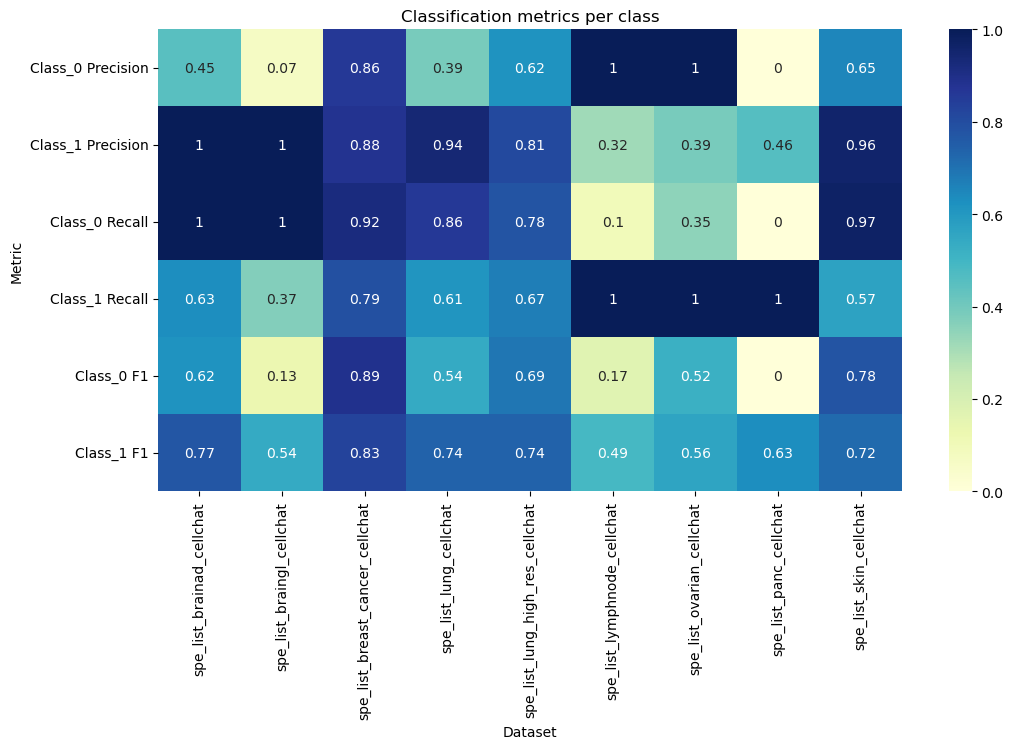

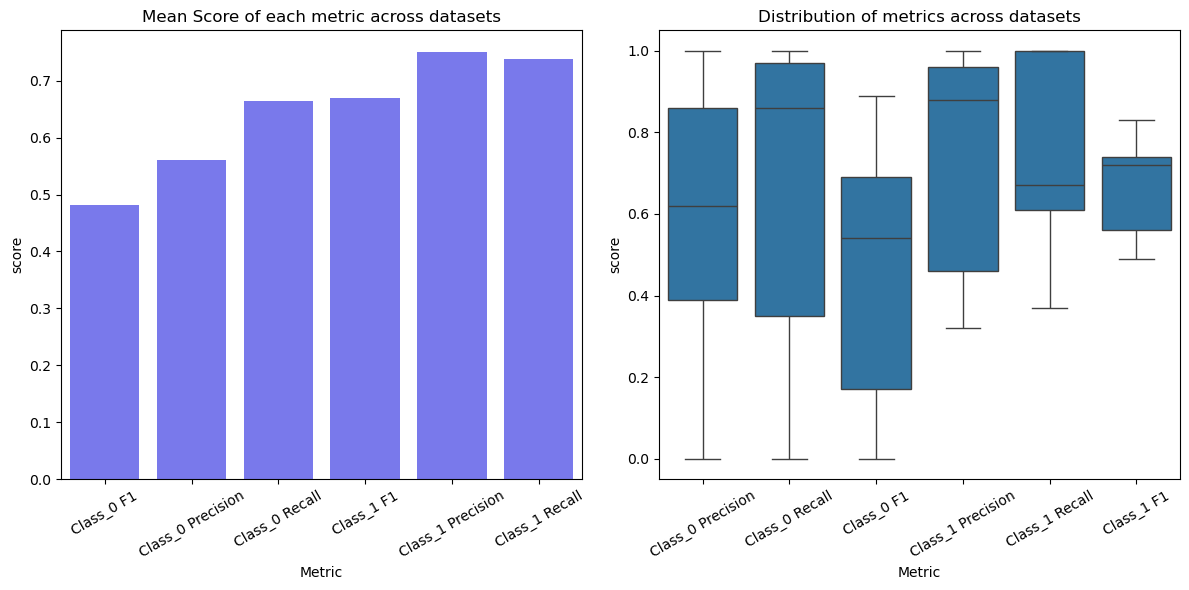

In [ ]:
# Per-class metrics plots
records = []
for ds, val in results.items():
    for line in val['class_report'].strip().split('\n'):
        if re.match(r'\s*\d+\s+', line):
            parts = line.strip().split()
            class_id = int(parts[0])
            records.append({'Dataset': ds, 'Metric': f'Class_{class_id} Precision', 'score': float(parts[1])})
            records.append({'Dataset': ds, 'Metric': f'Class_{class_id} Recall', 'score': float(parts[2])})
            records.append({'Dataset': ds, 'Metric': f'Class_{class_id} F1', 'score': float(parts[3])})

df = pd.DataFrame(records)
desired_order = ['Class_0 Precision',  'Class_1 Precision', 'Class_0 Recall', 'Class_1 Recall', 'Class_0 F1',  'Class_1 F1']
pivot_df = df.pivot(index='Metric', columns='Dataset', values='score')
mean_model = df.groupby("Metric")["score"].mean().reset_index()

# heatmap of per-class metrics
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_df.loc[['Class_0 Precision', 'Class_1 Precision', 'Class_0 Recall', 'Class_1 Recall', 'Class_0 F1', 'Class_1 F1'],:], annot=True, cmap="YlGnBu")
plt.title("Classification metrics per class")
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.barplot(data=mean_model, x="Metric", y="score", color='blue', alpha=0.6)
plt.xticks(rotation=30)
plt.title("Mean Score of each metric across datasets")
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="Metric", y="score")
plt.title("Distribution of metrics across datasets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
perclass_metrics = df

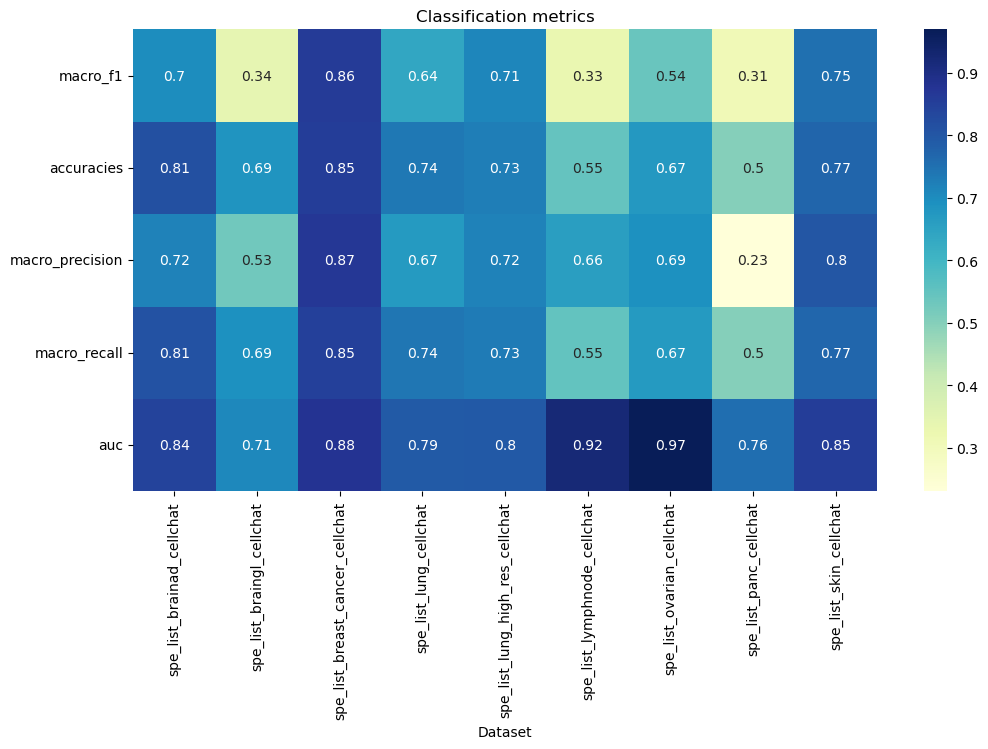

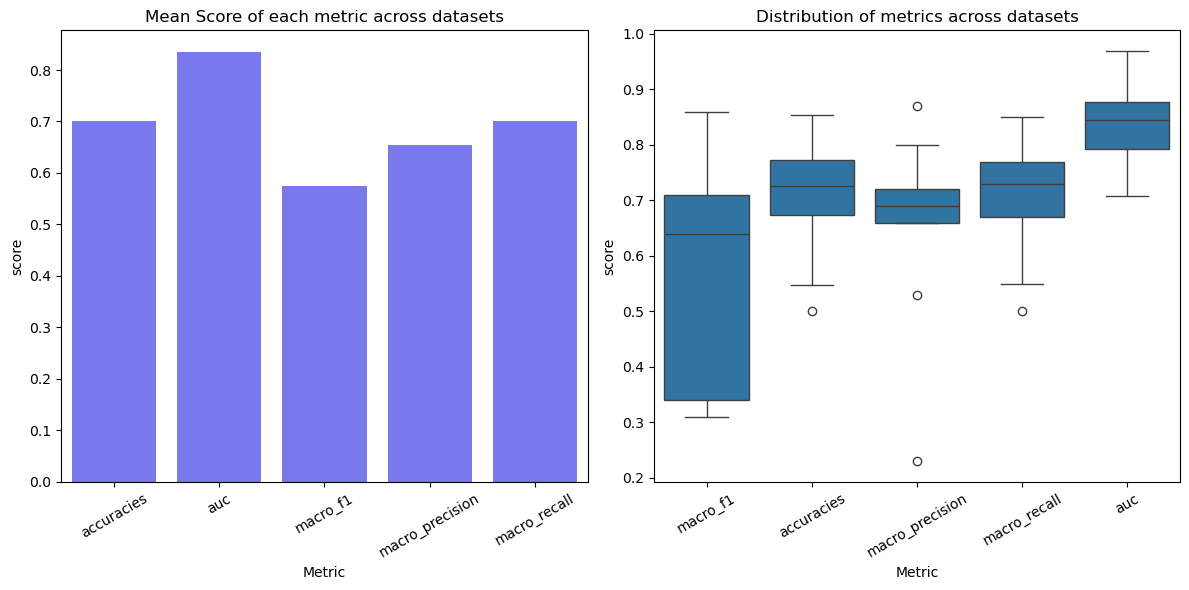

In [ ]:
# 
df = pd.DataFrame({
    'Dataset': datasets,
    'macro_f1': macro_f1,
    'accuracies': accuracies,
    'macro_precision': macro_precision,
    'macro_recall': macro_recall,
    'auc' : auc
})
melted_df = df.melt(id_vars='Dataset', 
                    value_vars=['macro_f1', 'accuracies', 'macro_precision', 'macro_recall', 'auc'], 
                    var_name='Metric', value_name='score')
mean_model = melted_df.groupby("Metric")["score"].mean().reset_index()

df.index = df['Dataset']
df = df.drop(columns=['Dataset'])
# heatmap 
plt.figure(figsize=(12, 6))
sns.heatmap(df.T,annot=True, cmap="YlGnBu")
plt.title("Classification metrics")
# barplot and boxplot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.barplot(data=mean_model, x="Metric", y="score", color='blue', alpha=0.6)
plt.xticks(rotation=30)
plt.title("Mean Score of each metric across datasets")
plt.subplot(1, 2, 2)
sns.boxplot(data=melted_df, x="Metric", y="score")
plt.title("Distribution of metrics across datasets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
class_metrics = melted_df

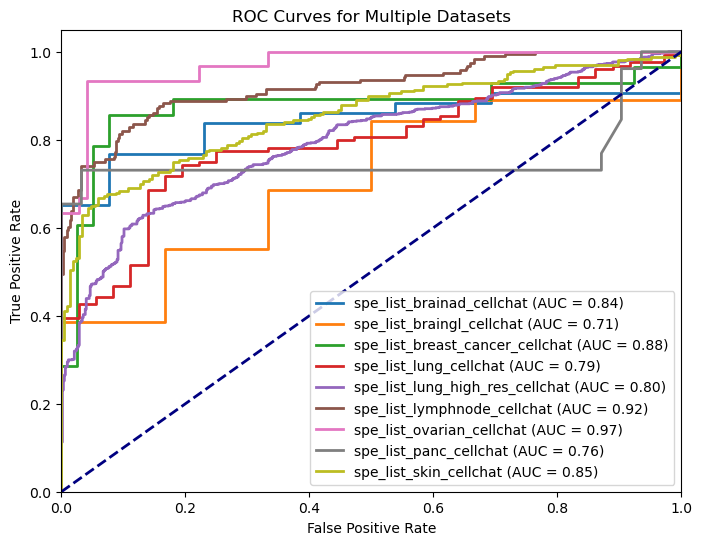

In [ ]:
plt.figure(figsize=(8, 6))
for i, (dataset_name, df) in enumerate(roc_tables.items()):
    fpr = df['False Positive Rate']
    tpr = df['True Positive Rate']
    roc_auc = auc[i]  
    plt.plot(
        fpr, tpr, lw=2,
        label=f'{dataset_name} (AUC = {roc_auc:.2f})'
    )
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Multiple Datasets')
plt.legend(loc="lower right")
plt.show()

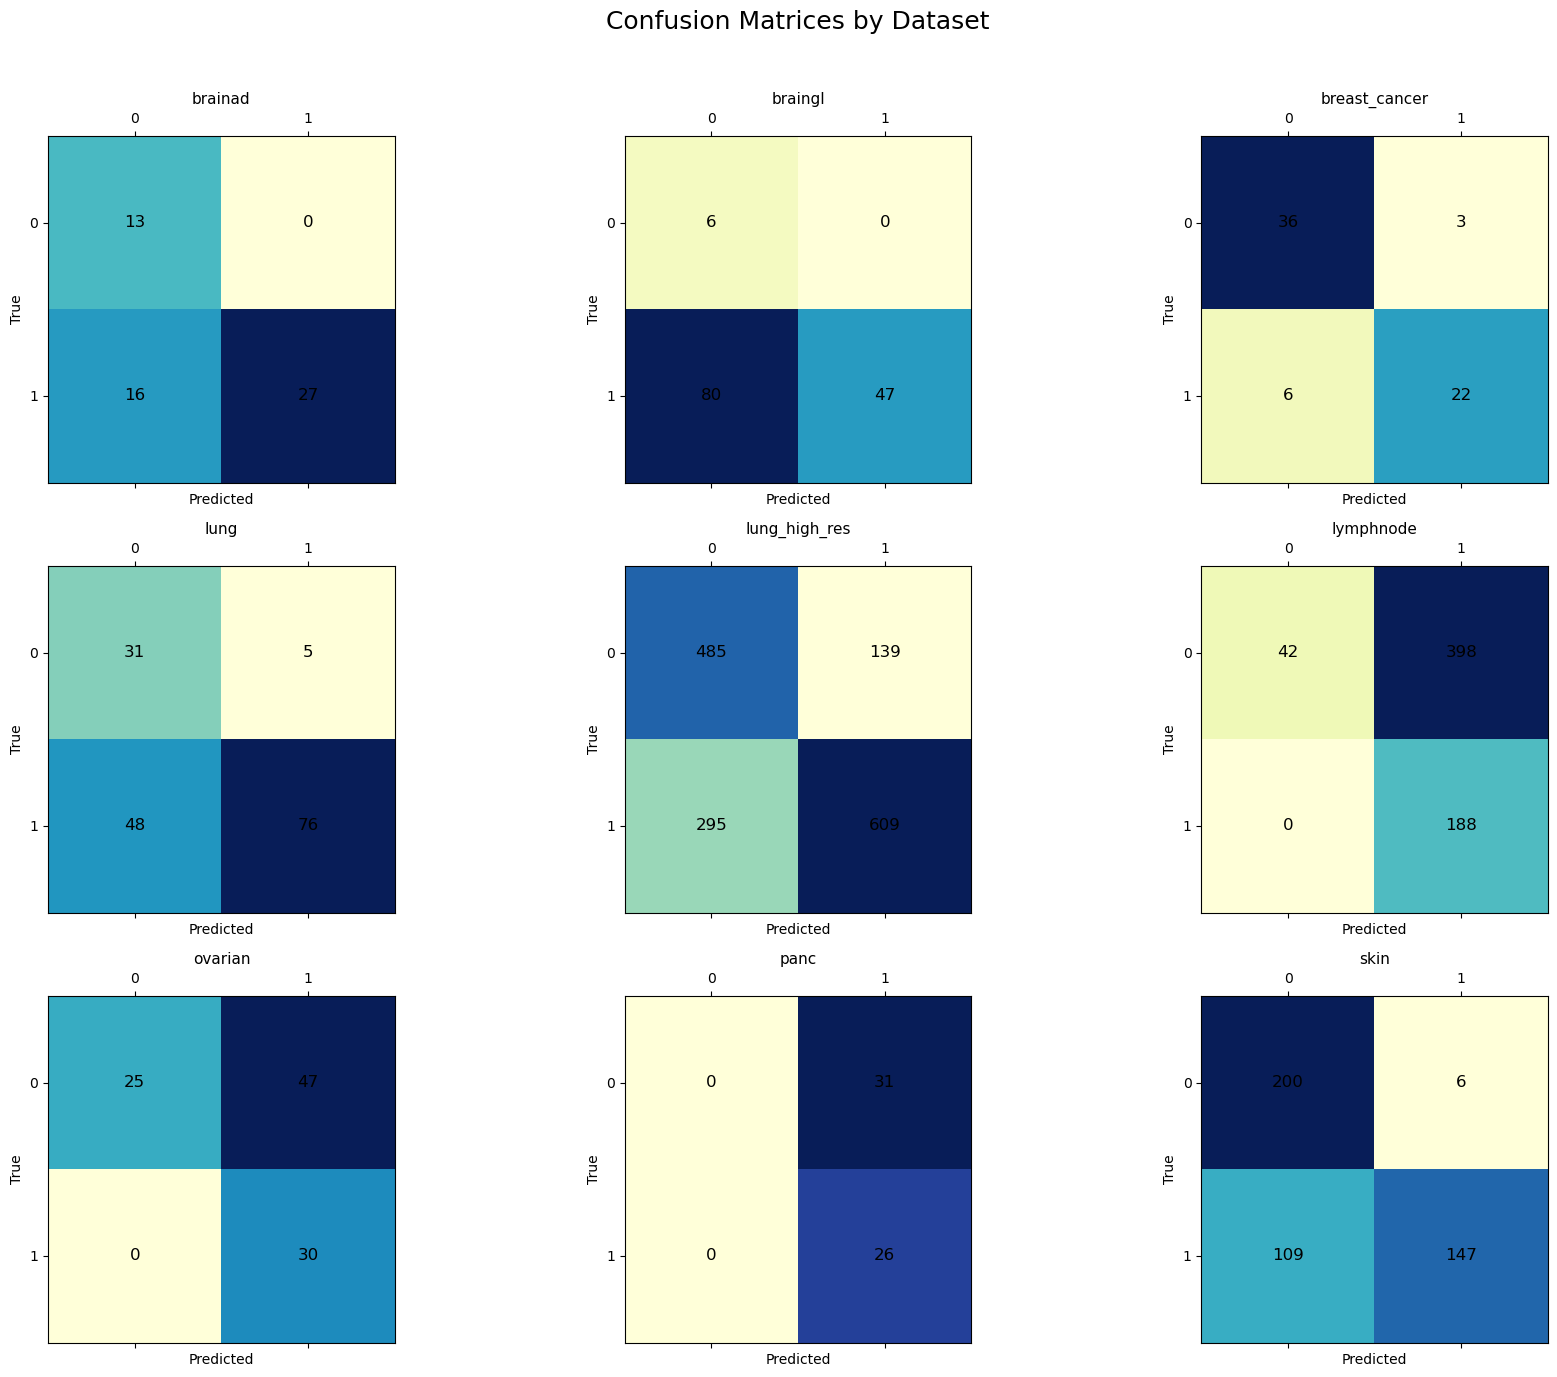

In [ ]:
# confusion matrices
results = {k: {'cm': v['cm']} for k, v in classification_metrics.items() if 'cm' in v}
fig, axs = plt.subplots(3, 3, figsize=(18, 14))
axs = axs.flatten()
custom_cmap = 'YlGnBu'  
for i, (dataset, data) in enumerate(results.items()):
    cm = data['cm']
    ax = axs[i]
    cax = ax.matshow(cm, cmap=custom_cmap)
    for (x, y), value in np.ndenumerate(cm):
        ax.text(y, x, str(value), va='center', ha='center', color='black', fontsize=12)
    ax.set_title(dataset.replace('spe_list_', '').replace('_cellchat', ''), fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
fig.suptitle('Confusion Matrices by Dataset', fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Panel B: Metrics of Regression -> Nucleus and cytoplasmic regression barplots or MSE and NMSE and R2 

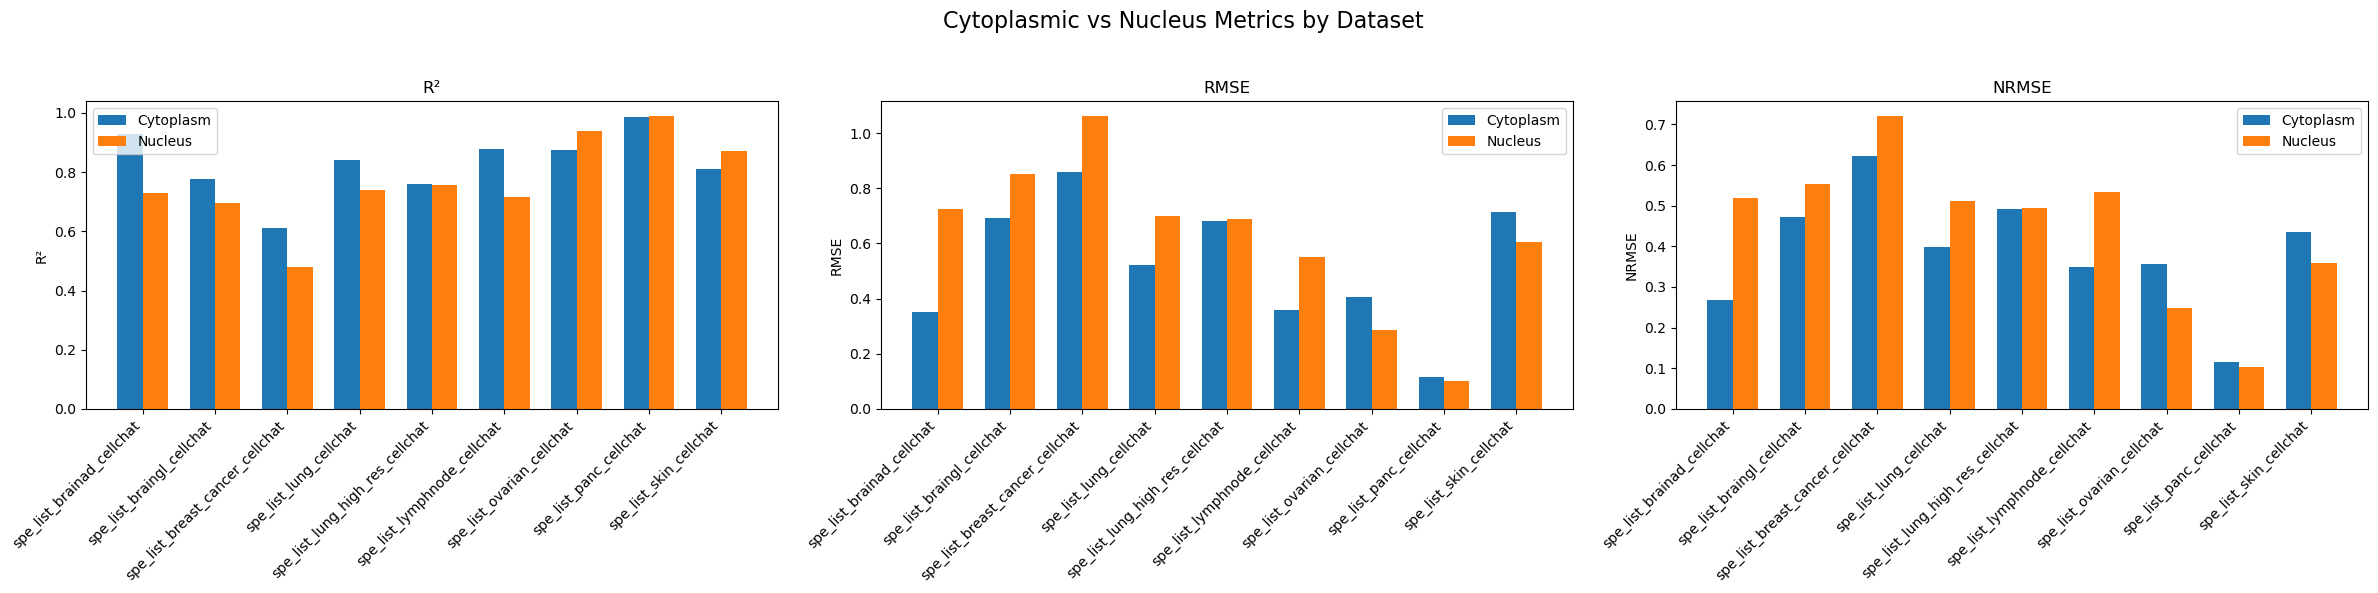

In [ ]:
cyt_df = pd.DataFrame(cyt_metrics).T
cyt_df.index.name = 'Dataset'
cyt_df.reset_index(inplace=True)
cyt_df.columns = [cyt_df.columns[0]] + ["cyt_" + col for col in cyt_df.columns[1:]]
nuc_df = pd.DataFrame(nuc_metrics).T
nuc_df.index.name = 'Dataset'
nuc_df.reset_index(inplace=True)
nuc_df.columns = [nuc_df.columns[0]] + ["nuc_" + col for col in nuc_df.columns[1:]]

merged_df = pd.merge(cyt_df, nuc_df, on='Dataset')
metrics = ['R²', 'RMSE', 'NRMSE']
compartments = ['Cytoplasm', 'Nucleus']

metrics = [
    ('cyt_R²', 'nuc_R²', 'R²'),
    ('cyt_RMSE', 'nuc_RMSE', 'RMSE'),
    ('cyt_NRMSE', 'nuc_NRMSE', 'NRMSE')
]

x = np.arange(len(merged_df['Dataset'])) 
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(24, 6), sharex=False)
for ax, (cyt_col, nuc_col, metric_name) in zip(axes, metrics):
    ax.bar(x - width/2, merged_df[cyt_col], width, label='Cytoplasm')
    ax.bar(x + width/2, merged_df[nuc_col], width, label='Nucleus')
    ax.set_xticks(x)
    ax.set_xticklabels(merged_df['Dataset'], rotation=45, ha='right')
    ax.set_ylabel(metric_name)
    ax.set_title(metric_name)
    ax.legend()
fig.suptitle("Cytoplasmic vs Nucleus Metrics by Dataset", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
reg = merged_df

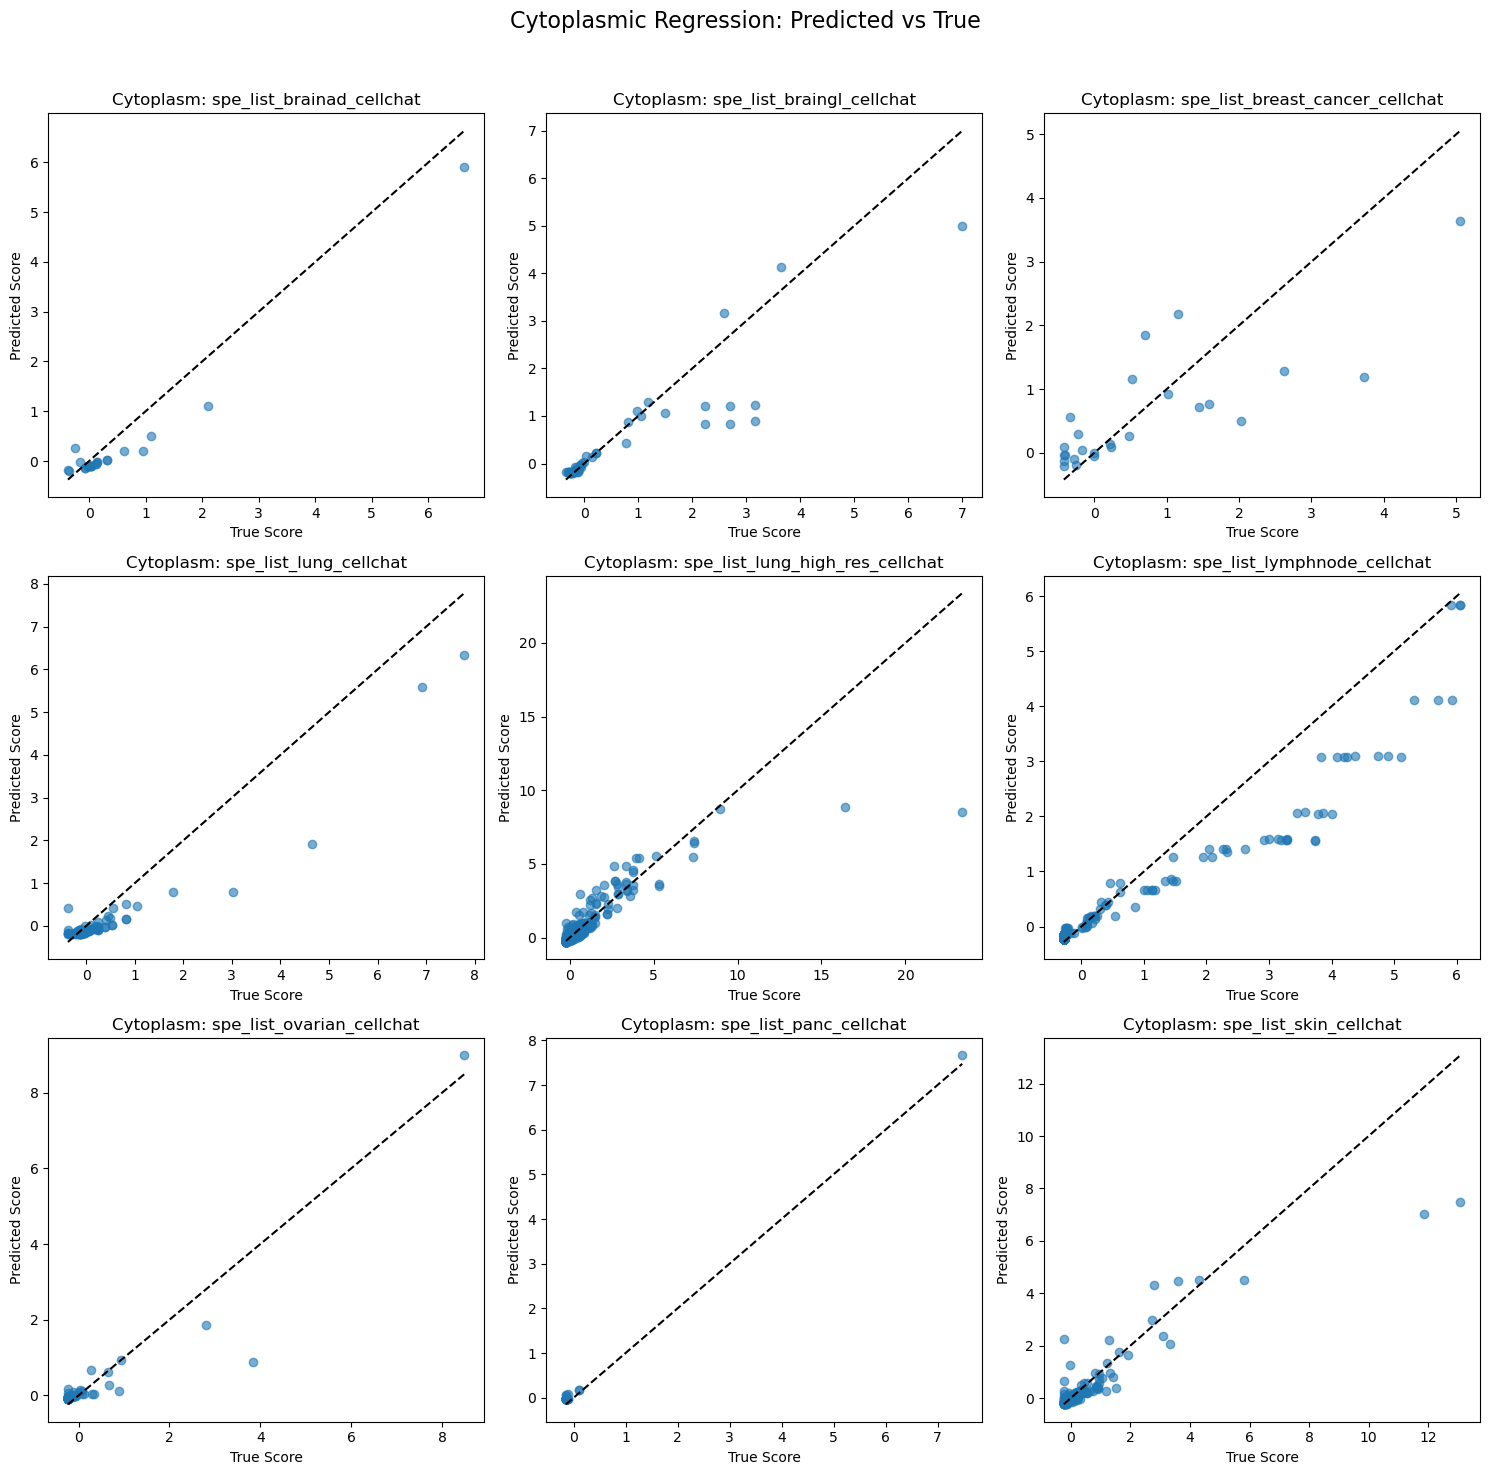

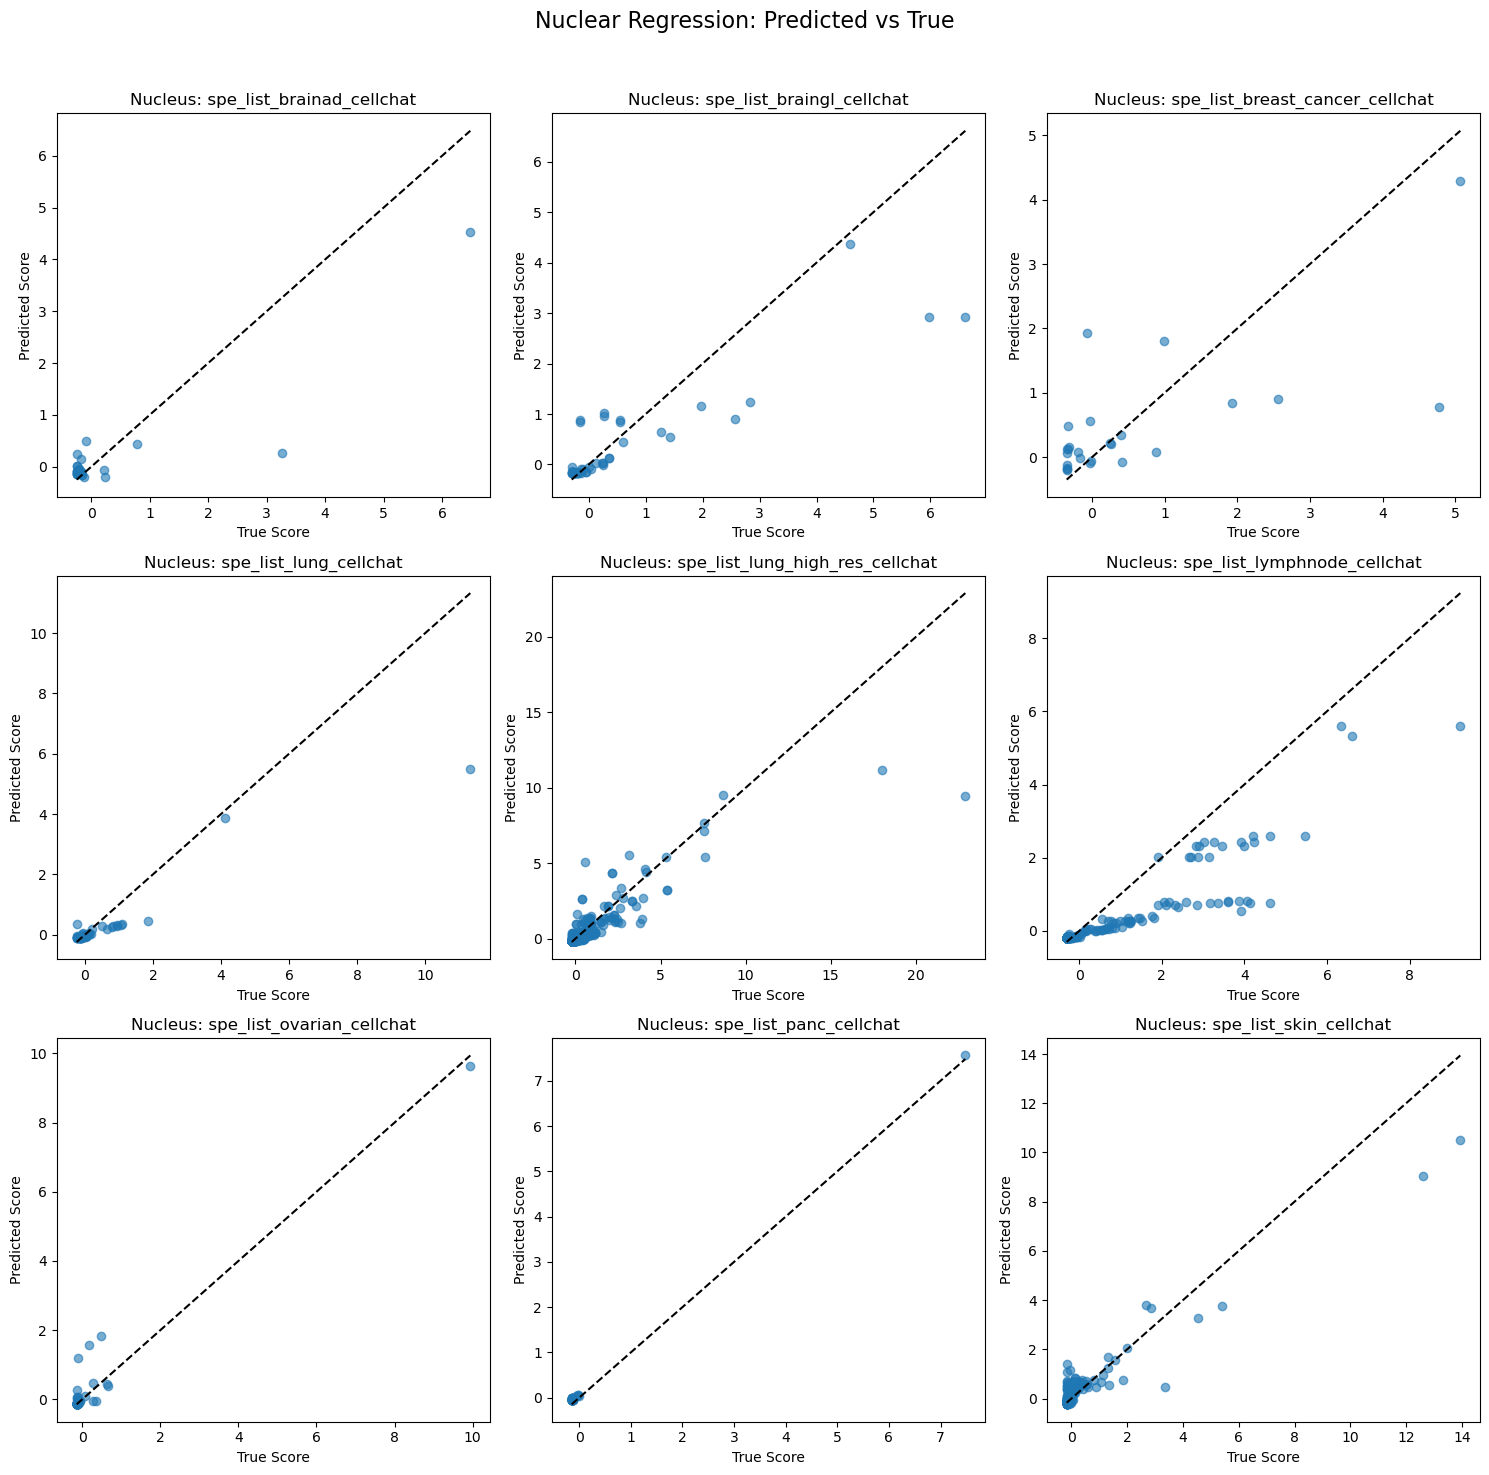

In [ ]:
n_plots = len(scatter_data_cyt)
n_rows, n_cols = 3, 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 15))
axes = axes.flatten()
model1f_regression = pd.concat([cyt_df, nuc_df.iloc[:,1:4]], axis = 1) 
# Plot each subplot
for i, (group, d) in enumerate(scatter_data_cyt.items()):
    ax = axes[i]
    ax.scatter(d['true'], d['pred'], alpha=0.6)
    ax.plot([min(d['true']), max(d['true'])], [min(d['true']), max(d['true'])], 'k--')
    ax.set_title(d['title'])
    ax.set_xlabel("True Score")
    ax.set_ylabel("Predicted Score")
# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle("Cytoplasmic Regression: Predicted vs True", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()
for i, (group, d) in enumerate(scatter_data_nuc.items()):
    ax = axes[i]
    ax.scatter(d['true'], d['pred'], alpha=0.6)
    ax.plot([min(d['true']), max(d['true'])], [min(d['true']), max(d['true'])], 'k--')
    ax.set_title(d['title'])
    ax.set_xlabel("True Score")
    ax.set_ylabel("Predicted Score")
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle("Nuclear Regression: Predicted vs True", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Panel C: Weighted metrics of heirarchial model

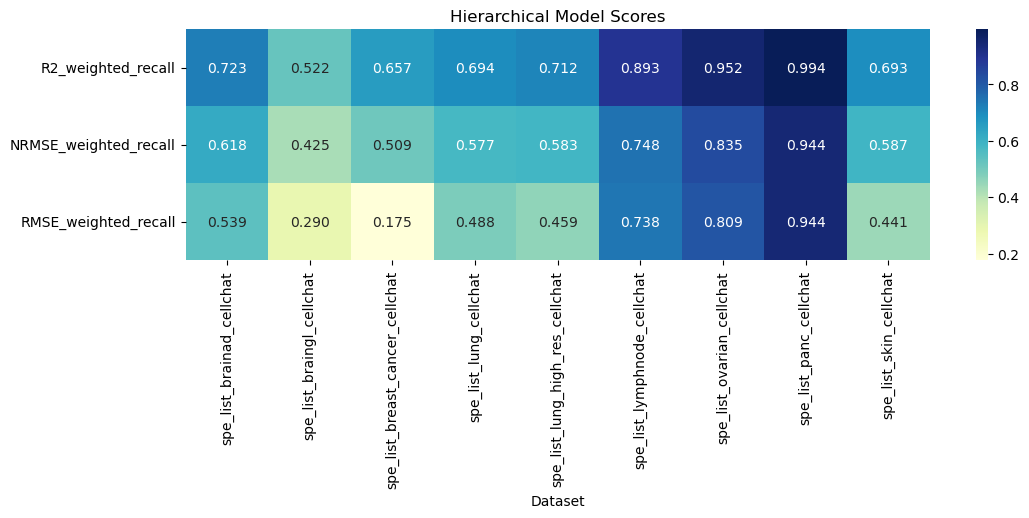

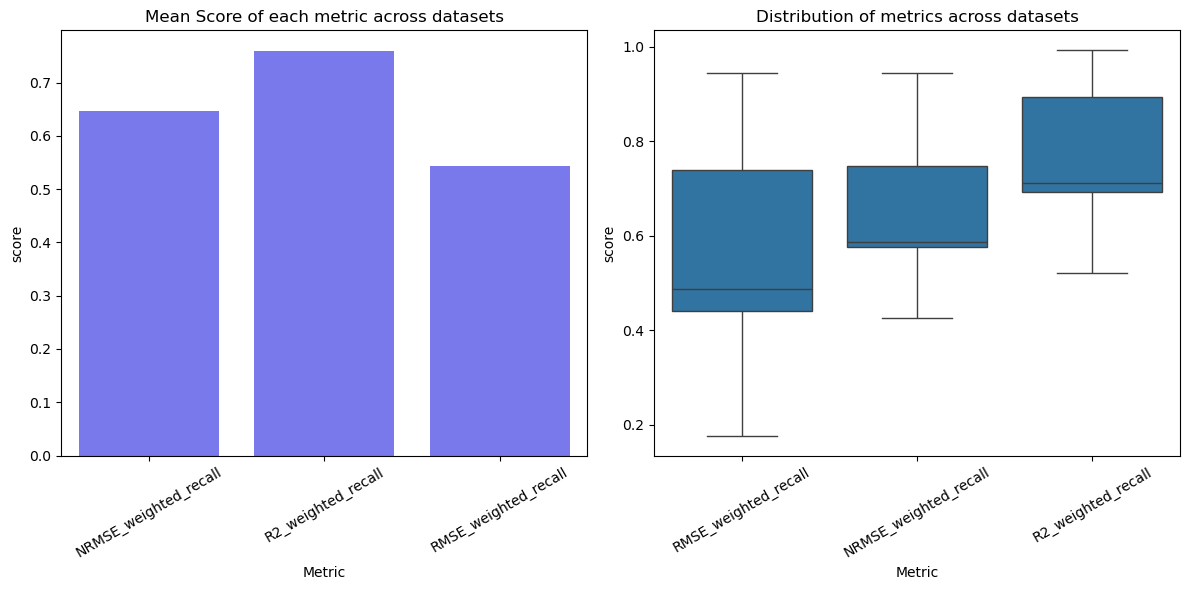

In [18]:
x_r2 = (merged_df['cyt_R²'] + merged_df['nuc_R²']) / 2
x_r2.index = merged_df['Dataset']
df = pd.DataFrame({
    'Dataset': x_r2.index,
    'R2_weighted_recall': np.sqrt(pivot_df.loc['Class_1 Recall'] * x_r2)
})
x_nrmse = 1 - (merged_df['cyt_NRMSE'] + merged_df['nuc_NRMSE']) / 2
x_nrmse.index = merged_df['Dataset']
df['NRMSE_weighted_recall'] = np.sqrt(pivot_df.loc['Class_1 Recall'] * x_nrmse)
x_rmse = 1 - (merged_df['cyt_RMSE'] + merged_df['nuc_RMSE']) / 2
x_rmse.index = merged_df['Dataset']
df['RMSE_weighted_recall'] = np.sqrt(pivot_df.loc['Class_1 Recall'] * x_rmse)
df.reset_index(drop=True, inplace=True)
melted_df = df.melt(id_vars='Dataset', 
                    value_vars=['RMSE_weighted_recall', 'NRMSE_weighted_recall', 'R2_weighted_recall'], 
                    var_name='Metric', value_name='score')
mean_model = melted_df.groupby("Metric")["score"].mean().reset_index()

df.index = df['Dataset']
df = df.drop(columns=['Dataset'])
plt.figure(figsize=(12, 3))
sns.heatmap(df.T, annot=True, cmap="YlGnBu", fmt=".3f")
plt.title("Hierarchical Model Scores")
plt.show()


plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.barplot(data=mean_model, x="Metric", y="score", color='blue', alpha=0.6)
plt.xticks(rotation=30)
plt.title("Mean Score of each metric across datasets")
plt.subplot(1, 2, 2)

sns.boxplot(data=melted_df, x="Metric", y="score")
plt.title("Distribution of metrics across datasets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [19]:
combined_metrics = melted_df

In [20]:
# wide the dataframe 
perclass_metrics = perclass_metrics.pivot(index='Dataset', columns='Metric', values='score').reset_index()
combined_metrics = combined_metrics.pivot(index='Dataset', columns='Metric', values='score').reset_index()
class_metrics = class_metrics.pivot(index='Dataset', columns='Metric', values='score').reset_index()

In [22]:
metrics = pd.merge(perclass_metrics, combined_metrics, on='Dataset').merge(class_metrics, on='Dataset').merge(reg, on='Dataset')
metrics.to_csv('../../data/processed/revisions/xgboost_voting_metrics.csv', index=False)

In [25]:
def scatterdict_to_df(scatter_dict, compartment):
    all_rows = []
    for group, d in scatter_dict.items():
        n = len(d['true'])

        # Make the true/pred/group/title columns
        base_df = pd.DataFrame({
            'group': group,
            'compartment': compartment,
            'true': np.asarray(d['true']).ravel(),
            'pred': np.asarray(d['pred']).ravel(),
            'title': d.get('title', f'{compartment}: {group}')
        })

        # Join with the ids DataFrame directly
        ids_df = d['ids'].reset_index(drop=True)
        merged_df = pd.concat([base_df.reset_index(drop=True), ids_df.reset_index(drop=True)], axis=1)

        all_rows.append(merged_df)

    return pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()

# Convert both scatter dicts
cyt_df_full = scatterdict_to_df(scatter_data_cyt, 'cytoplasm')
nuc_df_full = scatterdict_to_df(scatter_data_nuc, 'nucleus')

# Save to CSV
cyt_df_full.to_csv("../../data/results/predictions/scatter_data_cyt_fullmodel.csv", index=False)
nuc_df_full.to_csv("../../data/results/predictions/scatter_data_nuc_fullmodel.csv", index=False)